# Seller scorecard

A seller scorecard should answer one question fairly: **which sellers are doing their part of the job badly?** The earlier analyses showed that the two obvious measures, late rate and review score, mostly measure something else.

- Most late deliveries happen on the road, in a stage the seller does not control.
- Most bad reviews on late orders are written before the parcel arrives, because the survey is sent on the estimated delivery date.

On top of that, most sellers have so few orders that any rate calculated for them is mostly noise.

This notebook builds a scorecard that deals with all three problems: it measures what sellers control, uses only the reviews sellers earned, and adjusts every rate for how much evidence stands behind it.

## Scope

Delivered orders purchased between January 2017 and August 2018 that came from a single seller - 98.7% of all orders. An order with two sellers has one handoff time and one review, which cannot be split between them.

In [1]:
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import os

con = duckdb.connect("../olist.duckdb")

con.sql("""
    CREATE OR REPLACE VIEW model.v_delivery AS
    SELECT o.*, r.seller_state, r.customer_state, r.same_state, r.same_region, r.customer_region
    FROM model.fct_orders o
    LEFT JOIN model.dim_route r USING (route_key)
    WHERE purchase_date BETWEEN DATE '2017-01-01' AND DATE '2018-08-31'
""")

con.sql("""
    CREATE OR REPLACE TEMP VIEW seller_orders AS
    SELECT *,
        CASE WHEN weight_g IS NULL OR volume_cm3 IS NULL                 THEN 'Not sure'
             WHEN GREATEST(weight_g, volume_cm3 / 6.0) <  1000           THEN 'Small'
             WHEN GREATEST(weight_g, volume_cm3 / 6.0) <  5000           THEN 'Medium'
             WHEN GREATEST(weight_g, volume_cm3 / 6.0) < 20000           THEN 'Large'
             ELSE 'Oversize' END AS size_band
    FROM model.v_delivery
    WHERE n_sellers = 1
""")

def q(sql):
    return con.sql(sql).df()

def show(sql, n=30):
    con.sql(sql).show(max_rows=n)

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "font.size": 9,
})
print(f"single-seller orders: {con.execute('SELECT COUNT(*) FROM seller_orders').fetchall()[0][0]:,}")

single-seller orders: 94,931


---

## 1. What a seller controls

Each order item carries a **handoff deadline**: the date by which the seller has to give the parcel to the carrier. Meeting it is the seller's job; everything after it belongs to the carrier.

In [2]:
show("""
    SELECT
        CASE WHEN seller_missed_handoff THEN 'seller missed the handoff deadline'
             ELSE 'seller handed over on time' END      AS handoff,
        COUNT(*)                                        AS orders,
        ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct_of_orders,
        ROUND(MEDIAN(dispatch_days), 2)                 AS median_dispatch_days,
        ROUND(100 * AVG(is_late::INT), 2)               AS late_pct
    FROM seller_orders
    WHERE seller_missed_handoff IS NOT NULL
    GROUP BY 1 ORDER BY 1 DESC
""")

show("""
    SELECT ROUND(100.0 * AVG((NOT seller_missed_handoff)::INT), 1) AS pct_of_late_orders_with_on_time_handoff
    FROM seller_orders
    WHERE is_late AND seller_missed_handoff IS NOT NULL
""")

┌────────────────────────────────────┬────────┬───────────────┬──────────────────────┬──────────┐
│              handoff               │ orders │ pct_of_orders │ median_dispatch_days │ late_pct │
│              varchar               │ int64  │    double     │        double        │  double  │
├────────────────────────────────────┼────────┼───────────────┼──────────────────────┼──────────┤
│ seller missed the handoff deadline │   8530 │           9.0 │                 7.06 │    21.21 │
│ seller handed over on time         │  86400 │          91.0 │                 1.58 │     5.45 │
└────────────────────────────────────┴────────┴───────────────┴──────────────────────┴──────────┘

┌─────────────────────────────────────────┐
│ pct_of_late_orders_with_on_time_handoff │
│                 double                  │
├─────────────────────────────────────────┤
│                                    72.2 │
└─────────────────────────────────────────┘



Missing the handoff deadline matters: orders where the seller was late handing over are late for the customer about four times as often as orders where the seller was on time.

But the second table is the reason the late rate cannot be used to judge sellers. **Most late orders had a seller who handed over on time.** The delay happened afterwards, on the road. Ranking sellers by their late rate would mostly rank them by where their customers live and which carriers serve them.

So the main measure in this scorecard is the **handoff miss rate**: the share of a seller's orders handed to the carrier after the deadline.

---

## 2. Why a raw ranking does not work

The obvious next step would be to calculate each seller's rate and sort.

In [3]:
sellers = q("""
    WITH size_typical AS (
        SELECT size_band, MEDIAN(dispatch_days) AS typical_dispatch
        FROM seller_orders WHERE NOT timestamp_anomaly GROUP BY 1)
    SELECT
        o.main_seller_id                                                       AS seller_id,
        ANY_VALUE(o.seller_state)                                              AS seller_state,
        COUNT(*)                                                               AS orders,
        SUM(o.is_late::INT)                                                    AS late,
        SUM(COALESCE(o.seller_missed_handoff, FALSE)::INT)                     AS missed_handoff,
        SUM(o.dispatch_days - st.typical_dispatch) FILTER (WHERE NOT o.timestamp_anomaly)           AS dispatch_excess_sum,
        SUM(POWER(o.dispatch_days - st.typical_dispatch, 2)) FILTER (WHERE NOT o.timestamp_anomaly) AS dispatch_excess_sumsq,
        COUNT(o.dispatch_days) FILTER (WHERE NOT o.timestamp_anomaly)                               AS dispatch_n,
        MEDIAN(o.dispatch_days) FILTER (WHERE NOT o.timestamp_anomaly)                              AS median_dispatch_days,
        COUNT(*) FILTER (WHERE o.has_review)                                   AS reviews_all,
        AVG(o.review_score) FILTER (WHERE o.has_review)                        AS raw_review,
        COUNT(*) FILTER (WHERE o.has_review AND NOT o.review_before_delivery)  AS reviews_after,
        SUM(o.review_score) FILTER (WHERE o.has_review AND NOT o.review_before_delivery)            AS review_after_sum,
        SUM(POWER(o.review_score, 2)) FILTER (WHERE o.has_review AND NOT o.review_before_delivery)  AS review_after_sumsq
    FROM seller_orders o
    JOIN size_typical st USING (size_band)
    GROUP BY 1
    ORDER BY 1
""")
sellers["late_rate"] = sellers["late"] / sellers["orders"]
sellers["handoff_miss_rate"] = sellers["missed_handoff"] / sellers["orders"]

print(f"sellers: {len(sellers):,}")
print(f"with fewer than 10 orders: {(sellers['orders'] < 10).sum():,}")
print(f"with 30 or more orders:    {(sellers['orders'] >= 30).sum():,}")
print(f"median orders per seller:  {sellers['orders'].median():.0f}")

print("\nThe ten 'worst' sellers by raw late rate:")
sellers.sort_values(["late_rate", "orders"], ascending=False).head(10)[["orders", "late", "late_rate"]]

sellers: 2,925
with fewer than 10 orders: 1,712
with 30 or more orders:    614
median orders per seller:  7

The ten 'worst' sellers by raw late rate:


,orders,late,late_rate
218,2,2.0,1.0
1207,2,2.0,1.0
1635,2,2.0,1.0
2177,2,2.0,1.0
2480,2,2.0,1.0
2621,2,2.0,1.0
224,1,1.0,1.0
237,1,1.0,1.0
284,1,1.0,1.0
300,1,1.0,1.0


Of 2,925 sellers, 1,712 have fewer than ten orders and the median seller has seven. The "worst ten" by raw late rate are all sellers with one or two orders, every one of them late. They may be terrible sellers or they may have been unlucky once or twice, and so few orders cannot tell those apart.

A ranking has to take account of how much evidence lies behind each number.

---

## 3. Weighing each rate by its evidence

The method used here is called **empirical Bayes shrinkage**, and the idea is simpler than the name.

Before seeing anything about a seller, the best guess for their rate is the platform average. Each order they complete adds evidence about what they are really like. So each seller's score is a blend of their own record and the platform average, and the more orders they have, the more weight their own record gets.

How much weight the average gets is not chosen by hand. It is estimated from established sellers with at least 30 orders, by comparing how much their rates actually differ with how much they would differ by chance alone. If sellers genuinely differ a lot, a seller's own record quickly dominates. If they barely differ, the average stays influential for longer. The result is expressed as a number of orders: the platform average counts as much as that many of the seller's own orders.

In [4]:
def beta_prior(rate, n, min_n=30):
    """Platform mean and strength, in orders, estimated from sellers with enough history."""
    r = rate[n >= min_n]
    mean, var = r.mean(), r.var()
    strength = mean * (1 - mean) / var - 1
    return mean, strength

handoff_mean, handoff_strength = beta_prior(sellers["handoff_miss_rate"], sellers["orders"])
late_mean, late_strength = beta_prior(sellers["late_rate"], sellers["orders"])

sellers["handoff_miss_adjusted"] = (sellers["missed_handoff"] + handoff_mean * handoff_strength) / (sellers["orders"] + handoff_strength)
sellers["late_rate_adjusted"] = (sellers["late"] + late_mean * late_strength) / (sellers["orders"] + late_strength)

pd.DataFrame({
    "platform mean %": [100 * handoff_mean, 100 * late_mean],
    "platform mean counts as this many orders": [handoff_strength, late_strength],
}, index=["handoff miss rate", "late rate"]).round(2)

,platform mean %,platform mean counts as this many orders
handoff miss rate,9.27,5.09
late rate,6.71,23.31


The two strengths are themselves a finding.

For the **handoff miss rate**, the platform average counts as only about five orders. Sellers genuinely differ a great deal in how reliably they hand over, so after a handful of orders a seller's own record is the better guide.

For the **late rate**, the average counts as about 23 orders. Sellers differ much less in their late rates than their raw numbers suggest; most of the variation is chance. This is the same conclusion as section 1 reached from a different direction: the late rate carries little information about the seller.

With the adjustment, the worst sellers are ones with a real track record.

In [5]:
cols = ["orders", "missed_handoff", "handoff_miss_rate", "handoff_miss_adjusted"]
sellers.sort_values("handoff_miss_adjusted", ascending=False).head(10)[cols].round(3)

,orders,missed_handoff,handoff_miss_rate,handoff_miss_adjusted
829,32,28.0,0.875,0.768
29,12,12.0,1.000,0.730
1537,40,31.0,0.775,0.698
1757,8,8.0,1.000,0.647
306,15,12.0,0.800,0.621
1732,9,8.0,0.889,0.601
2065,11,9.0,0.818,0.589
630,6,6.0,1.000,0.583
2451,6,6.0,1.000,0.583
2027,14,10.0,0.714,0.549


A seller who missed 28 of 32 deadlines ranks above one who missed 8 of 8, because 32 orders are much stronger evidence than eight - but both still rank near the top, because both records are clear.

---

## 4. The ratings a seller earned

The delivery analysis showed that reviews written before a parcel arrives are mostly complaints that it has not come, which says nothing about the seller. The scorecard therefore uses only reviews written **after** delivery.

Review scores are noisier than rates - a single customer can give one star or five for reasons unrelated to the seller - so the same kind of adjustment is applied. Here the blend uses the variation in scores within each seller against the variation between sellers.

In [6]:
after = sellers[sellers["reviews_after"] > 0].copy()
after["mean"] = after["review_after_sum"] / after["reviews_after"]
grand_mean = after["review_after_sum"].sum() / after["reviews_after"].sum()

est = after[after["reviews_after"] >= 30].copy()
est["var"] = (est["review_after_sumsq"] - est["reviews_after"] * est["mean"] ** 2) / (est["reviews_after"] - 1)
within_var = (est["var"] * (est["reviews_after"] - 1)).sum() / (est["reviews_after"] - 1).sum()
between_var = est["mean"].var() - (within_var / est["reviews_after"]).mean()
review_strength = within_var / between_var

sellers["review_after_raw"] = sellers["review_after_sum"] / sellers["reviews_after"]
sellers["review_adjusted"] = np.where(
    sellers["reviews_after"] > 0,
    (sellers["review_after_sum"].fillna(0) + grand_mean * review_strength) / (sellers["reviews_after"] + review_strength),
    grand_mean)

print(f"platform average review after delivery: {grand_mean:.2f}")
print(f"the average counts as this many reviews: {review_strength:.1f}")

platform average review after delivery: 4.31
the average counts as this many reviews: 25.2


Reviews written after delivery average 4.31, and the platform average counts as about 25 reviews. Individual reviews are noisy enough that a seller needs a couple of dozen before their own average says more than the platform's does.

---

## 5. Dispatch speed, allowing for parcel size

Handoff deadlines are set per item, so a seller who always ships on the last permitted day never misses one. Dispatch speed adds a second view of the seller's own stage.

The delivery analysis found that bulky orders take longer to dispatch, which is not the seller's fault. So each order's dispatch time is compared with the typical dispatch time for orders of the same size, and the seller's score is their average difference, adjusted for evidence in the same way as reviews.

Orders whose timestamps were flagged as inconsistent during cleaning - for example a carrier pickup recorded before the payment was approved - are left out of this measure, since they would produce negative dispatch times.

In [7]:
d = sellers[sellers["dispatch_n"] >= 30].copy()
d["mean"] = d["dispatch_excess_sum"] / d["dispatch_n"]
d["var"] = (d["dispatch_excess_sumsq"] - d["dispatch_n"] * d["mean"] ** 2) / (d["dispatch_n"] - 1)
dispatch_within = (d["var"] * (d["dispatch_n"] - 1)).sum() / (d["dispatch_n"] - 1).sum()
dispatch_between = d["mean"].var() - (dispatch_within / d["dispatch_n"]).mean()
dispatch_strength = dispatch_within / dispatch_between
dispatch_grand = sellers["dispatch_excess_sum"].sum() / sellers["dispatch_n"].sum()

sellers["dispatch_vs_typical_adjusted"] = (
    (sellers["dispatch_excess_sum"].fillna(0) + dispatch_grand * dispatch_strength)
    / (sellers["dispatch_n"] + dispatch_strength))

print(f"the platform average counts as this many orders: {dispatch_strength:.1f}")
sellers["dispatch_vs_typical_adjusted"].describe().round(2)

the platform average counts as this many orders: 1.8


count    2925.00
mean        1.12
std         2.16
min        -1.71
25%        -0.04
50%         0.52
75%         1.51
max        27.79
Name: dispatch_vs_typical_adjusted, dtype: float64

Sellers differ in dispatch speed even more than in handoff reliability: the platform average counts as fewer than two orders, so a seller's own record dominates almost immediately. A positive score means the seller is slower than is typical for the size of parcel they ship; a negative one, faster.

---

## 6. The scorecard

Each seller is placed in one of three groups on the measure they control most directly, the adjusted handoff miss rate. The thresholds are round numbers around the platform average of about 9%:

- **Reliable**: misses no more than 10% of handoff deadlines
- **Watch**: misses 10–20%
- **Needs attention**: misses more than 20%, about twice the platform average or worse

Rating and dispatch speed are shown alongside, not combined into a single score. A composite score would need weights that no data can justify, and it would hide which part of the job a seller is getting wrong.

Because sellers differ so much in handoff reliability, the adjustment lets a seller's own record count after only a few orders. A status based on a handful of orders is therefore provisional, and the number of orders behind each score is kept in the output so that it can be filtered on.

In [8]:
sellers["status"] = pd.cut(sellers["handoff_miss_adjusted"], [0, 0.10, 0.20, 1.0],
                           labels=["Reliable", "Watch", "Needs attention"], include_lowest=True)

summary = sellers.groupby("status", observed=True).agg(
    sellers=("seller_id", "size"),
    orders=("orders", "sum"),
    median_orders_per_seller=("orders", "median"),
    avg_review_adjusted=("review_adjusted", "mean"),
    late_pct=("late", lambda s: 100 * s.sum() / sellers.loc[s.index, "orders"].sum()),
)
summary["pct_of_orders"] = 100 * summary["orders"] / summary["orders"].sum()
summary.round(2)

,sellers,orders,median_orders_per_seller,avg_review_adjusted,late_pct,pct_of_orders
status,,,,,,
Reliable,2125,67562,6.0,4.33,5.94,71.17
Watch,383,15842,9.0,4.30,7.80,16.69
Needs attention,417,11527,7.0,4.26,11.04,12.14


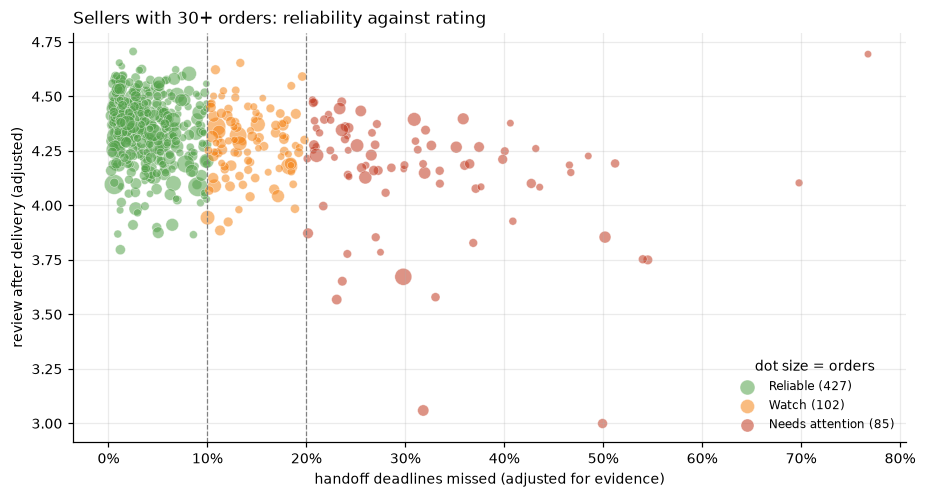

correlation between missed handoffs and rating, sellers with 30+ orders: -0.38


In [9]:
est = sellers[sellers["orders"] >= 30]

fig, ax = plt.subplots(figsize=(8.5, 4.6))
colors = {"Reliable": "#54A24B", "Watch": "#F58518", "Needs attention": "#C23B22"}
for status, g in est.groupby("status", observed=True):
    ax.scatter(100 * g["handoff_miss_adjusted"], g["review_adjusted"], s=np.sqrt(g["orders"]) * 4,
               alpha=0.55, color=colors[status], label=f"{status} ({len(g)})", edgecolor="white", linewidth=0.4)
ax.axvline(10, color="grey", linewidth=0.8, linestyle="--")
ax.axvline(20, color="grey", linewidth=0.8, linestyle="--")
ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_xlabel("handoff deadlines missed (adjusted for evidence)")
ax.set_ylabel("review after delivery (adjusted)")
ax.set_title("Sellers with 30+ orders: reliability against rating", loc="left", fontsize=11)
ax.legend(frameon=False, fontsize=8, title="dot size = orders")
plt.tight_layout()
plt.show()

print(f"correlation between missed handoffs and rating, sellers with 30+ orders: "
      f"{est['handoff_miss_adjusted'].corr(est['review_adjusted']):.2f}")

About seven in ten orders come from Reliable sellers. Among established sellers, those who miss more handoffs also earn lower ratings from customers whose parcels did arrive, with a correlation of −0.38. The two measures point the same way without being the same thing, which is why both stay on the scorecard.

---

## 7. How much the method changes the answer

The point of the adjustments is that they change which sellers are singled out. Taking the 10% of established sellers (30+ orders) who look worst under each approach shows by how much.

In [10]:
est = sellers[sellers["orders"] >= 30].copy()
k = int(len(est) * 0.10)

worst_by_late      = set(est.nlargest(k, "late_rate_adjusted")["seller_id"])
worst_by_handoff   = set(est.nlargest(k, "handoff_miss_adjusted")["seller_id"])
worst_by_raw_rev   = set(est.nsmallest(k, "raw_review")["seller_id"])
worst_by_fair_rev  = set(est.nsmallest(k, "review_adjusted")["seller_id"])

print(f"established sellers: {len(est)}; the worst 10% = {k} sellers\n")
print(f"worst by late rate that are also worst by missed handoffs:   {len(worst_by_late & worst_by_handoff)} of {k}")
print(f"worst by all reviews that are also worst by earned reviews:  {len(worst_by_raw_rev & worst_by_fair_rev)} of {k}")

only_late = est[est["seller_id"].isin(worst_by_late - worst_by_handoff)]
print(f"\nsellers flagged only by late rate: median handoff miss rate "
      f"{100 * only_late['handoff_miss_rate'].median():.1f}% (platform about {100 * handoff_mean:.1f}%)")

established sellers: 614; the worst 10% = 61 sellers

worst by late rate that are also worst by missed handoffs:   23 of 61
worst by all reviews that are also worst by earned reviews:  46 of 61

sellers flagged only by late rate: median handoff miss rate 8.5% (platform about 9.3%)


The choice of measure matters far more than the review correction.

Judged by late rate, and judged by missed handoffs, the two lists of the worst 10% share only about a third of their sellers. The sellers that only the late rate flags typically hand over on time, slightly more reliably than the platform as a whole; they look bad because of what happens after their part of the job is done. Acting on a late-rate ranking would mean warning sellers who are doing their job, and missing many who are not.

Using only reviews written after delivery changes the list less, about a quarter of the sellers, but it removes ratings the seller did nothing to deserve.

---

## 8. Saving the scorecard

The scorecard is saved with every seller, including those with few orders, together with the number of orders behind each score, so the dashboard can filter on how much evidence a user wants to see.

In [11]:
scorecard = sellers[[
    "seller_id", "seller_state", "orders", "status",
    "handoff_miss_rate", "handoff_miss_adjusted",
    "median_dispatch_days", "dispatch_vs_typical_adjusted",
    "reviews_after", "review_after_raw", "review_adjusted",
    "late_rate", "late_rate_adjusted", "raw_review",
]].copy()
scorecard["status"] = scorecard["status"].astype(str)

con.sql("CREATE OR REPLACE TABLE model.seller_scorecard AS SELECT * FROM scorecard")

out = "../outputs/model"
os.makedirs(out, exist_ok=True)
scorecard.to_csv(f"{out}/seller_scorecard.csv", index=False)

show("SELECT status, COUNT(*) AS sellers FROM model.seller_scorecard GROUP BY 1 ORDER BY 2 DESC")

┌─────────────────┬─────────┐
│     status      │ sellers │
│     varchar     │  int64  │
├─────────────────┼─────────┤
│ Reliable        │    2125 │
│ Needs attention │     417 │
│ Watch           │     383 │
└─────────────────┴─────────┘



---

## 9. What this analysis establishes

**Sellers should be judged on the handoff, not the delivery.** Missing the handoff deadline makes an order about four times more likely to be late, but most late orders had a seller who handed over on time.

**Raw rankings are dominated by sellers with almost no history.** The median seller has seven orders, and the "worst" sellers by raw late rate all have one or two. Weighing each rate by its evidence fixes this, and the weights themselves are informative: sellers differ strongly in how reliably they hand over, but barely differ in late rate beyond chance.

**The choice of measure changes who gets flagged.** The worst 10% of established sellers by late rate and by missed handoffs share only about a third of their members, and the sellers flagged only by late rate hand over more reliably than average.

**Ratings should only count reviews the seller earned.** Reviews written before delivery are mostly about the delivery not having happened. Removing them changes about a quarter of the worst-rated sellers.

**The scorecard keeps its measures separate.** Handoff reliability sets the status; rating and dispatch speed sit alongside it, so a seller can see which part of the job needs work.

In [12]:
con.close()
print("connection closed")

connection closed
